<a href="https://colab.research.google.com/github/rahs2015/mat422/blob/main/MAT422_%7C_HW_3_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#MAT 422 | HW 3.4: Logistic Regression

In [9]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.set_printoptions(precision=4, suppress=True)

#3.4.1: Sigmoid/logistic function
The sigmoid function takes any real number and converts it into a number between 0 to 1. This really gives the ability to display possibiliites as they must also lie between 0 to 1. With this example, using -4, -2, 0, 2, 4, the results are printed and shown through the output changes when the input increase.

Input values: [-4 -2  0  2  4]
Sigmoid values: [0.01798621 0.11920292 0.5        0.88079708 0.98201379]


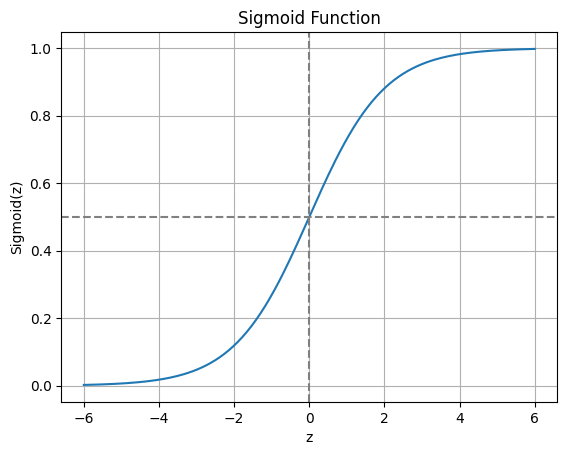

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

values = np.array([-4, -2, 0, 2, 4])

print("Input values:", values)
print("Sigmoid values:", sigmoid(values))

z = np.linspace(-6, 6, 200)

plt.plot(z, sigmoid(z))
plt.axhline(0.5, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("z")
plt.ylabel("Sigmoid(z)")
plt.title("Sigmoid Function")
plt.grid()
plt.show()

#3.4.2: Binary classification probabilities
Binary classification is used to predict one of two possible outcomes usually by 0 to 1. Logistic regression estimates the probability of a specific observation which can be used to make predictions. We create an array containing five example which were then assigned a threshold of .5 to determine the class for each observation.

In [12]:
X, y = make_classification(
    n_samples=150,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=1.3,
    random_state=422
)
model = LogisticRegression()
model.fit(X, y)

predictions = model.predict(X)
probabilities = model.predict_proba(X)

print("Model coefficients:", model.coef_)
print("Model intercept:", model.intercept_)
print("First five probabilities of class 1:")
print(probabilities[:5, 1])

print("Training accuracy:", accuracy_score(y, predictions))
print("Confusion matrix:")
print(confusion_matrix(y, predictions))

Model coefficients: [[ 2.8175 -2.0447]]
Model intercept: [-2.7847]
First five probabilities of class 1:
[0.8005 0.8883 0.0047 0.065  0.009 ]
Training accuracy: 0.98
Confusion matrix:
[[75  1]
 [ 2 72]]


#3.4.3: Logistic regression fitting and interpretation
Logistic regrssion is a machine learning method that learns relationships between input features and outcomes with 2 possible classes. The model is used to estiamte the probability of an observation and then uses a threshold to continue to predict future classes. We calculate the training accuracy and compares the predicted classes with the actual classes. The outputs shows the logistic regression estimates the probability of each observation, and the confusion matrix shows how many observations were classified correctly.

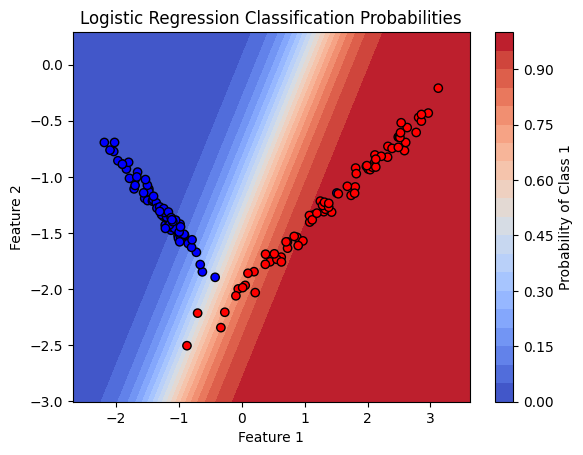

In [11]:
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 150),
    np.linspace(y_min, y_max, 150)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_probabilities = model.predict_proba(grid)[:, 1]
grid_probabilities = grid_probabilities.reshape(xx.shape)

plt.contourf(xx, yy, grid_probabilities, levels=20, cmap="coolwarm")
plt.colorbar(label="Probability of Class 1")

plt.scatter(
    X[:, 0], X[:, 1],
    c=y, cmap="bwr", edgecolors="black"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic Regression Classification Probabilities")
plt.show()

* I explained my sections in words before my code.
* I double checked my core numerical claims such as expression, matrix multiplication, norms, ...
* I changed and/or extended at least one to make this homework my own.
* I ran this from to bottom without issues.
* I am saving this to github under my mat422 repository.